# 03. Effort analysis: manual review before vs after the workflow

**Business question:** how much manual verification effort does the workflow remove?

* **Before:** the legacy process applied exact-match exception rules to the raw record (missing field, any street
  ending that is not a standard abbreviation, PO box or unit in line 1, ZIP/city/state not exactly matching the
  reference, repeated name + address). Every exception went to a person, who fixed it by hand.
* **After:** only NEEDS_REVIEW and INVALID records reach a person (INVALID ones need patient outreach). Everything
  else is released automatically, with a small QA spot-check of auto-corrections.

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = '../reports/figures'
from reference import load_zip_reference
raw = pd.read_csv('../data/raw/address_records.csv', dtype=str, keep_default_na=False)
ref = load_zip_reference('../data/raw/zip_reference.csv')
from workflow import legacy_exceptions
res = pd.read_csv('../data/processed/workflow_results.csv', dtype=str, keep_default_na=False)
legacy = legacy_exceptions(raw, ref)
df = raw[['record_id', 'source_system', 'created_at']].merge(legacy, on='record_id').merge(res[['record_id', 'status', 'reasons']], on='record_id')
df['manual_after'] = df.status.isin(['NEEDS_REVIEW', 'INVALID'])
print(f'{len(df):,} records')

49,920 records


## 1. Share of records needing a person

In [2]:
before = df.legacy_exception.mean()
after = df.manual_after.mean()
reduction = 1 - after / before
summary = pd.DataFrame({'records needing manual handling': [df.legacy_exception.sum(), df.manual_after.sum()],
                        'share of all records': [before, after]}, index=['before (legacy rules)', 'after (workflow)'])
print(f'manual share {before:.1%} -> {after:.1%}: {reduction:.1%} fewer records need a person')
summary.round(4)

manual share 33.6% -> 7.2%: 78.6% fewer records need a person


,records needing manual handling,share of all records
before (legacy rules),16776,0.3361
after (workflow),3591,0.0719


In [3]:
flags = df.legacy_flags.str.split('|').explode()
leg = flags[flags != ''].value_counts().rename('records').to_frame()
leg['share'] = (leg.records / len(df)).round(4)
print('Legacy exception triggers (a record can trigger several):')
leg

Legacy exception triggers (a record can trigger several):


,records,share
legacy_flags,,
nonstandard_line1,8527,0.1708
zip_city_state_mismatch,6291,0.1260
missing_field,2886,0.0578
no_house_number,1707,0.0342
duplicate,1440,0.0288


In [4]:
flow = pd.crosstab(df.legacy_exception.map({True: 'legacy exception', False: 'legacy pass'}), df.status)[
    ['VERIFIED', 'AUTO_CORRECTED', 'NEEDS_REVIEW', 'INVALID']]
print('Where the legacy exceptions end up in the new workflow:')
flow

Where the legacy exceptions end up in the new workflow:


status,VERIFIED,AUTO_CORRECTED,NEEDS_REVIEW,INVALID
legacy_exception,,,,
legacy exception,385,13291,2552,548
legacy pass,32653,0,491,0


## 2. Effort in hours
Assumptions (stated, not measured): a manual check and fix takes 4 minutes per record in both processes; INVALID
records need patient outreach at 10 minutes; QA spot-checks 5% of AUTO_CORRECTED records at 1 minute each. A
sensitivity table follows.

In [5]:
def hours(review_min=4, outreach_min=10, qa_rate=0.05, qa_min=1):
    b = df.legacy_exception.sum() * review_min / 60
    invalid_b = (df.legacy_exception & (df.status == 'INVALID')).sum()
    b += invalid_b * (outreach_min - review_min) / 60          # outreach was needed before too
    a = (df.status == 'NEEDS_REVIEW').sum() * review_min / 60 + (df.status == 'INVALID').sum() * outreach_min / 60
    a += (df.status == 'AUTO_CORRECTED').sum() * qa_rate * qa_min / 60
    return b, a

b, a = hours()
print(f'analyst hours for this file: before {b:,.0f} h, after {a:,.0f} h -> {1 - a / b:.1%} less effort')
sens = pd.DataFrame([{'review_min': r, 'qa_rate': q, 'effort reduction': 1 - hours(review_min=r, qa_rate=q)[1] / hours(review_min=r, qa_rate=q)[0]}
                     for r in [3, 4, 6] for q in [0.0, 0.05, 0.10]])
sens.pivot(index='review_min', columns='qa_rate', values='effort reduction').round(3)

analyst hours for this file: before 1,173 h, after 305 h -> 74.0% less effort


qa_rate,0.00,0.05,0.10
review_min,,,
3,0.730,0.718,0.706
4,0.749,0.740,0.730
6,0.769,0.763,0.756


## 3. Weekly workload

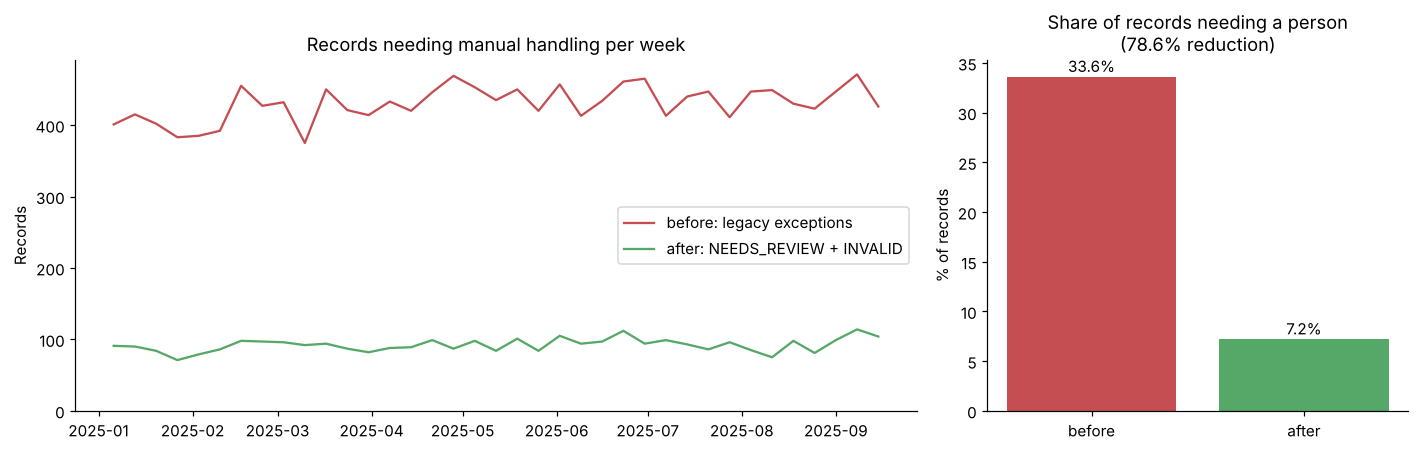

average week: 1,288 records, 430 manual before, 92 after


In [6]:
df['week'] = pd.to_datetime(df.created_at).dt.to_period('W').dt.start_time
weekly = df.groupby('week').agg(records=('record_id', 'count'), before=('legacy_exception', 'sum'), after=('manual_after', 'sum'))
weekly = weekly.iloc[1:-1]  # drop partial first and last weeks
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [2, 1]})
axes[0].plot(weekly.index, weekly.before, label='before: legacy exceptions', color='#C44E52')
axes[0].plot(weekly.index, weekly.after, label='after: NEEDS_REVIEW + INVALID', color='#55A868')
axes[0].set_title('Records needing manual handling per week'); axes[0].set_ylabel('Records'); axes[0].legend()
axes[0].set_ylim(0)
axes[1].bar(['before', 'after'], [before * 100, after * 100], color=['#C44E52', '#55A868'])
for i, v in enumerate([before * 100, after * 100]):
    axes[1].text(i, v + 0.5, f'{v:.1f}%', ha='center')
axes[1].set_title(f'Share of records needing a person\n({reduction:.1%} reduction)'); axes[1].set_ylabel('% of records')
plt.tight_layout(); plt.savefig(f'{FIG}/effort_before_after.png', bbox_inches='tight'); plt.show()
print(f'average week: {weekly.records.mean():,.0f} records, {weekly.before.mean():,.0f} manual before, {weekly.after.mean():,.0f} after')

## 4. By source system

In [7]:
by_src = df.groupby('source_system').agg(records=('record_id', 'count'), before=('legacy_exception', 'mean'), after=('manual_after', 'mean'))
by_src['reduction'] = 1 - by_src.after / by_src.before
by_src.round(3)

,records,before,after,reduction
source_system,,,,
CALL_CENTER,9877,0.348,0.077,0.778
EHR_INTAKE,20076,0.331,0.070,0.789
PARTNER_FEED,4955,0.326,0.067,0.795
PATIENT_PORTAL,15012,0.339,0.073,0.785


In [8]:
pd.DataFrame({'before_share': [before], 'after_share': [after], 'record_reduction': [reduction],
              'hours_before': [b], 'hours_after': [a], 'hours_reduction': [1 - a / b]}).round(4).to_csv(
    '../data/processed/effort_summary.csv', index=False)

## Findings

* The legacy exception rules sent **16,776 records (33.6%)** to a person; after the workflow **3,591 (7.2%)** need
  one. That is **78.6% fewer records needing manual review**.
* In analyst time (4 minutes per review, 10 minutes per INVALID outreach, 5% QA sampling of auto-corrections) the
  effort drops from **1,173 to 305 hours** for this file, a **74.0% reduction**. Across the sensitivity grid the
  reduction stays between 70.6% and 76.9%.
* Most legacy exceptions were formatting and reference mismatches that the workflow now fixes itself: 13,291 of
  them are auto-corrected and 385 (clean PO boxes) are verified. 491 records that the legacy rules passed now go to
  review, mostly near-duplicate re-submissions the exact-match rule could not see.
* An average week has about 1,288 new records: roughly 430 manual checks before vs 92 after. The reduction is
  consistent across source systems (77.8% to 79.5%).